# O+O with ISR: the medium and the hadrons

One job of [`run_prod_oo_isr.py`](README.md): O+O 200 GeV, PythiaIsrGun + iMATTER (ISR),
MUSIC, Matter in the medium, iColored jet hadronization.

1. **The medium.** MUSIC's energy density in the transverse plane at η_s ≈ 0, at three
   proper times, with the freeze-out contour and the hard scattering (vertex and the dijet's
   transverse directions).
2. **The hadrons.** η, φ and pT distributions of the bulk (iSS) and the jet hadrons
   (iColoredHadronization), per event, and the azimuth relative to the leading hard parton.

**Input.** A job's `<stem>.h5` (hydro), `<stem>_hadrons_bulk_bg.h5` and
`<stem>_hadrons_jet_frag.h5`, e.g. from

```bash
python run_prod_oo_isr.py --events 20 --seed 1 --bulk-hadrons 100 --no-particlize
```

The bulk file can also come from `hadronize.py --tags bulk_bg` on the particlize file
(README, *Hadronization*). Set `OO_STEM` (environment) or `STEM` below to the job's stem.

In [1]:
%matplotlib inline
import os
import h5py
try:  # registers Blosc, the default compression of the production files
    import hdf5plugin  # noqa: F401
except ImportError:
    print("note: pip install hdf5plugin -- needed for Blosc-compressed files")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

# The job to read: run_prod_oo_isr.py writes ./out/OO_isr_seed<NNNN>.*
STEM = os.environ.get("OO_STEM", "out/OO_isr_seed0001")
EV = 0                          # event for the medium maps (row of the hydro file)
TAUS = (0.6, 1.5, 3.0)          # proper times of the three maps [fm/c]
XY_LIM = 6.0                    # the maps show |x|, |y| < XY_LIM [fm]
CHARGED_ONLY = False            # hadron plots: charged hadrons only
ETA_CUT = 1.0                   # |eta| < ETA_CUT for the phi, pT and delta-phi plots

# X-SCAPE build with MUSIC's EOS tables, for the freeze-out contour (optional)
BUILD = os.environ.get("XSCAPE_BUILD") or os.path.join(os.environ.get("XSCAPE", "../../../../../.."),
                                                       "build_gpu")
T_FO = 0.15                     # MUSIC freeze-out temperature of the production [GeV]

# --- one fixed visual language ---------------------------------------------------------------
# Bulk and jet hadrons have ASSIGNED hues (never swapped): blue bulk, orange jet.  The energy
# density uses the scheme of ../prod_AuAu_0_10_jet/jet_wake.ipynb: inferno on a log scale from
# e_fo/10, freeze-out as a white dashed contour.
C_BULK, C_JET = "#2a78d6", "#eb6834"
C_INK, C_MUTED = "#0b0b0b", "#52514e"
CMAP_E = plt.get_cmap("inferno").with_extremes(under="black", bad="black")
C_DIJET = "#56B4E9"             # the dijet arrows on the maps (visible on inferno)
plt.rcParams.update({
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK, "xtick.color": C_MUTED,
    "ytick.color": C_MUTED, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2.0, "figure.dpi": 110})

for suffix in ("", "_hadrons_bulk_bg", "_hadrons_jet_frag"):
    path = STEM + suffix + ".h5"
    print(f"{'found  ' if os.path.exists(path) else 'MISSING'} {path}")

found   out/OO_isr_seed0001.h5
found   out/OO_isr_seed0001_hadrons_bulk_bg.h5
found   out/OO_isr_seed0001_hadrons_jet_frag.h5


## 1. The medium

`<stem>.h5` holds MUSIC's evolution resampled on `grid_oo.yaml`: `arr` is
(event, feature, x, y, η_s, τ) with features (e, vx, vy, vz), e in GeV/fm³. With 32 η_s cells
there is no cell at η_s = 0; the two middle cells (±0.156) are averaged.

In [2]:
with h5py.File(STEM + ".h5") as f:
    a = f.attrs
    nev_hydro = f["arr"].shape[0]
    x = a["x_min"] + a["dx"] * np.arange(f["arr"].shape[2])
    y = a["y_min"] + a["dy"] * np.arange(f["arr"].shape[3])
    neta = f["arr"].shape[4]
    tau = a["tau_min"] + a["dtau"] * np.arange(f["arr"].shape[5])
    mid = [neta // 2 - 1, neta // 2] if neta % 2 == 0 else [neta // 2]
    e_mid = f["arr"][EV, 0, :, :, mid, :].mean(axis=2)          # (x, y, tau)
    tau_fo = float(f["tau_freezeout"][EV])
    diag = {k: f["diag"][k][()] for k in f["diag"]}
    system = a.get("system", "")

def d(key):
    return diag[key][EV] if key in diag else np.nan

print(f"{system}: {nev_hydro} events in the hydro file")
print(f"event {EV}: pTHat {d('pthat'):.1f} GeV, Npart {d('glauber_npart'):.0f}, "
      f"Ncoll {d('glauber_ncoll'):.0f}, {d('glauber_nstrings'):.0f} strings, b {d('glauber_b'):.2f} fm, "
      f"MUSIC tau0 {d('tau0_music'):.2f} fm/c, freeze-out at tau {tau_fo:.2f} fm/c")

# freeze-out energy density e(T_FO) from MUSIC's hotQCD table (EOS 9: rows e, P, s, T)
E_FO = None
eos = os.path.join(BUILD, "EOS", "hotQCD", "hrg_hotqcd_eos_binary.dat")
if os.path.exists(eos):
    tab = np.fromfile(eos, dtype="<f8").reshape(-1, 4)
    E_FO = float(np.interp(T_FO, tab[:, 3], tab[:, 0]))
    print(f"freeze-out contour: e(T = {T_FO} GeV) = {E_FO:.3f} GeV/fm^3")
else:
    print(f"no EOS table at {eos}: no freeze-out contour (set XSCAPE_BUILD)")

O+O 200 GeV, b in [0.0, 3.0] fm: 20 events in the hydro file
event 0: pTHat 21.9 GeV, Npart 20, Ncoll 20, 21 strings, b 2.86 fm, MUSIC tau0 0.48 fm/c, freeze-out at tau 4.18 fm/c
freeze-out contour: e(T = 0.15 GeV) = 0.234 GeV/fm^3


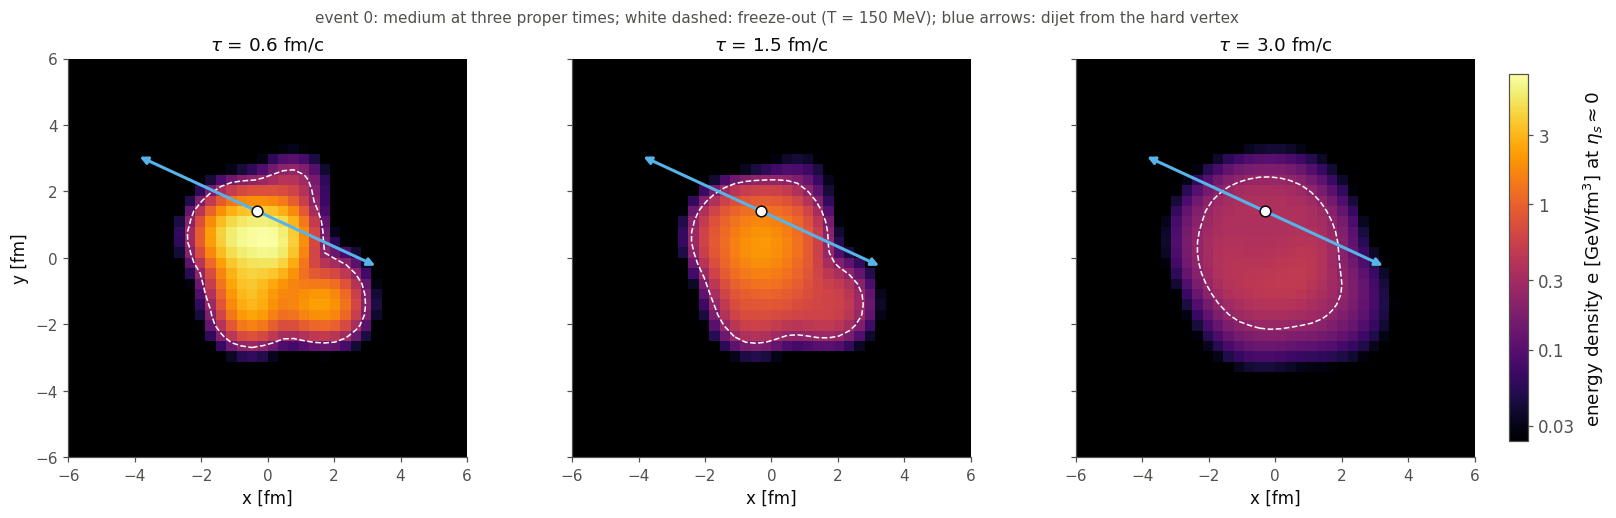

In [3]:
# The hard scattering of this event: vertex and transverse directions of the two hardest
# shower initiators (the dijet), from the jet hadron file's initiators/
hard = None
jet_path = STEM + "_hadrons_jet_frag.h5"
if os.path.exists(jet_path):
    with h5py.File(jet_path) as f:
        if "initiators" in f:
            cols = list(f["initiators"].attrs["columns"])
            off = f["initiators/offsets"][:]
            # unit u of the jet file is event units/event[u]; find this event's unit
            ev_of_unit = f["units/event"][:]
            row = diag["event"][EV] if "event" in diag else EV
            u = int(np.flatnonzero(ev_of_unit == row)[0])
            ini = f["initiators/data"][off[u]:off[u + 1]]
            pt = np.hypot(ini[:, cols.index("px")], ini[:, cols.index("py")])
            top = ini[np.argsort(pt)[::-1][:2]]
            hard = {"x": top[0, cols.index("x")], "y": top[0, cols.index("y")],
                    "px": top[:, cols.index("px")], "py": top[:, cols.index("py")],
                    "pt": np.hypot(top[:, cols.index("px")], top[:, cols.index("py")])}

# one log scale for the three maps: from e_fo/10 (as jet_wake.ipynb) to the largest e shown
ks = [int(np.argmin(np.abs(tau - t))) for t in TAUS]
e_max = float(max(e_mid[:, :, k].max() for k in ks))
e_min = E_FO / 10 if E_FO is not None else 1e-2 * e_max
norm = LogNorm(vmin=e_min, vmax=e_max)
ticks = [v for v in (0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100) if e_min <= v <= e_max]

fig, axes = plt.subplots(1, len(TAUS), figsize=(4.6 * len(TAUS) + 1.4, 4.6),
                         constrained_layout=True, sharey=True)
for ax, k in zip(np.atleast_1d(axes), ks):
    frame = e_mid[:, :, k]
    im = ax.pcolormesh(x, y, np.where(frame > 0, frame, np.nan).T, cmap=CMAP_E, norm=norm,
                       shading="auto")
    if E_FO is not None and frame.max() > E_FO:
        ax.contour(x, y, frame.T, levels=[E_FO], colors="w", linewidths=1.0, linestyles="--")
    if hard is not None:
        scale = 4.0 / hard["pt"].max()                             # longest arrow 4 fm
        for px, py in zip(hard["px"], hard["py"]):
            ax.annotate("", xy=(hard["x"] + scale * px, hard["y"] + scale * py),
                        xytext=(hard["x"], hard["y"]),
                        arrowprops=dict(arrowstyle="-|>", color=C_DIJET, lw=2), zorder=5)
        ax.plot(hard["x"], hard["y"], marker="o", ms=7, mfc="white", mec=C_INK, mew=1,
                ls="none", zorder=6)
    after = tau[k] > tau_fo
    ax.set_title(f"$\\tau$ = {tau[k]:.1f} fm/c" + ("  (after freeze-out)" if after else ""),
                 color=C_INK, fontsize=12)
    ax.set_xlabel("x [fm]", fontsize=11)
    ax.set_xlim(-XY_LIM, XY_LIM); ax.set_ylim(-XY_LIM, XY_LIM)
    ax.set_aspect("equal")
    ax.set_facecolor("black")
    ax.grid(False)
np.atleast_1d(axes)[0].set_ylabel("y [fm]", fontsize=11)
cb = fig.colorbar(im, ax=axes, shrink=0.92, pad=0.02)
cb.set_label("energy density e [GeV/fm$^3$] at $\\eta_s \\approx 0$", fontsize=12)
cb.ax.yaxis.set_major_locator(FixedLocator(ticks))
cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
cb.ax.yaxis.set_minor_locator(NullLocator())
cb.ax.tick_params(labelsize=11)
fig.suptitle(f"event {EV}: medium at three proper times"
             + ("; white dashed: freeze-out (T = 150 MeV)" if E_FO is not None else "")
             + ("; blue arrows: dijet from the hard vertex" if hard is not None else ""),
             color=C_MUTED, fontsize=10)
plt.show()

## 2. The hadrons

Both hadron files have one unit per event. The bulk unit holds N oversamples (independent
Cooper-Frye samplings of the same fluid), so the bulk is normalized **per event and per
sample**; the jet file has one sample per event. The jet hadrons are those of the whole
hard-scattered nucleon pair: dijet, MPI partons, ISR emissions and beam remnants.

In [4]:
CHARGED = (211, 321, 2212, 3222, 3112, 3312, 3334, 11, 13)

def load_hadrons(path):
    # -> dict with pT, eta, phi, the per-hadron weight 1/(N_events * N_samples of its event),
    #    the event of each hadron, and the number of events / samples
    with h5py.File(path) as f:
        p = f["hadrons/p"][:].astype(np.float64)
        pid = f["hadrons/pid"][:]
        so = f["hadrons/sample_offsets"][:]
        uo = f["hadrons/unit_offsets"][:]
        events = f["units/event"][:] if "units/event" in f else np.arange(len(uo) - 1)
    n_units = len(uo) - 1
    n_samp = np.diff(uo)                                   # samples per unit
    rows_per_unit = so[uo[1:]] - so[uo[:-1]]
    unit = np.repeat(np.arange(n_units), rows_per_unit)
    w = 1.0 / (n_units * np.maximum(n_samp[unit], 1))
    pt = np.hypot(p[:, 1], p[:, 2])
    pabs = np.sqrt(pt ** 2 + p[:, 3] ** 2)
    eta = 0.5 * np.log(np.clip(pabs + p[:, 3], 1e-300, None) / np.clip(pabs - p[:, 3], 1e-300, None))
    phi = np.arctan2(p[:, 2], p[:, 1])
    keep = np.isin(np.abs(pid), CHARGED) if CHARGED_ONLY else np.ones(len(pid), bool)
    return {"pt": pt[keep], "eta": eta[keep], "phi": phi[keep], "w": w[keep],
            "event": events[unit][keep], "n_units": n_units, "n_samples": n_samp}

H = {}
for tag, path in (("bulk", STEM + "_hadrons_bulk_bg.h5"), ("jet", STEM + "_hadrons_jet_frag.h5")):
    if os.path.exists(path):
        H[tag] = load_hadrons(path)
        h = H[tag]
        print(f"{tag:4s}: {h['n_units']} events, {int(np.median(h['n_samples']))} sample(s) per "
              f"event, {len(h['pt'])} {'charged ' if CHARGED_ONLY else ''}hadrons, "
              f"dN/deta(|eta| < 0.5) = {h['w'][np.abs(h['eta']) < 0.5].sum():.1f} per event")

# the leading hard parton's azimuth per event (for delta-phi), from the jet file's initiators
phi_lead = {}
if os.path.exists(jet_path):
    with h5py.File(jet_path) as f:
        if "initiators" in f:
            cols = list(f["initiators"].attrs["columns"])
            off, data, ev_of_unit = f["initiators/offsets"][:], f["initiators/data"][:], f["units/event"][:]
            for u, e in enumerate(ev_of_unit):
                ini = data[off[u]:off[u + 1]]
                if len(ini):
                    i = np.argmax(np.hypot(ini[:, cols.index("px")], ini[:, cols.index("py")]))
                    phi_lead[int(e)] = np.arctan2(ini[i, cols.index("py")], ini[i, cols.index("px")])

bulk: 20 events, 100 sample(s) per event, 783559 hadrons, dN/deta(|eta| < 0.5) = 45.7 per event
jet : 20 events, 1 sample(s) per event, 2397 hadrons, dN/deta(|eta| < 0.5) = 32.6 per event


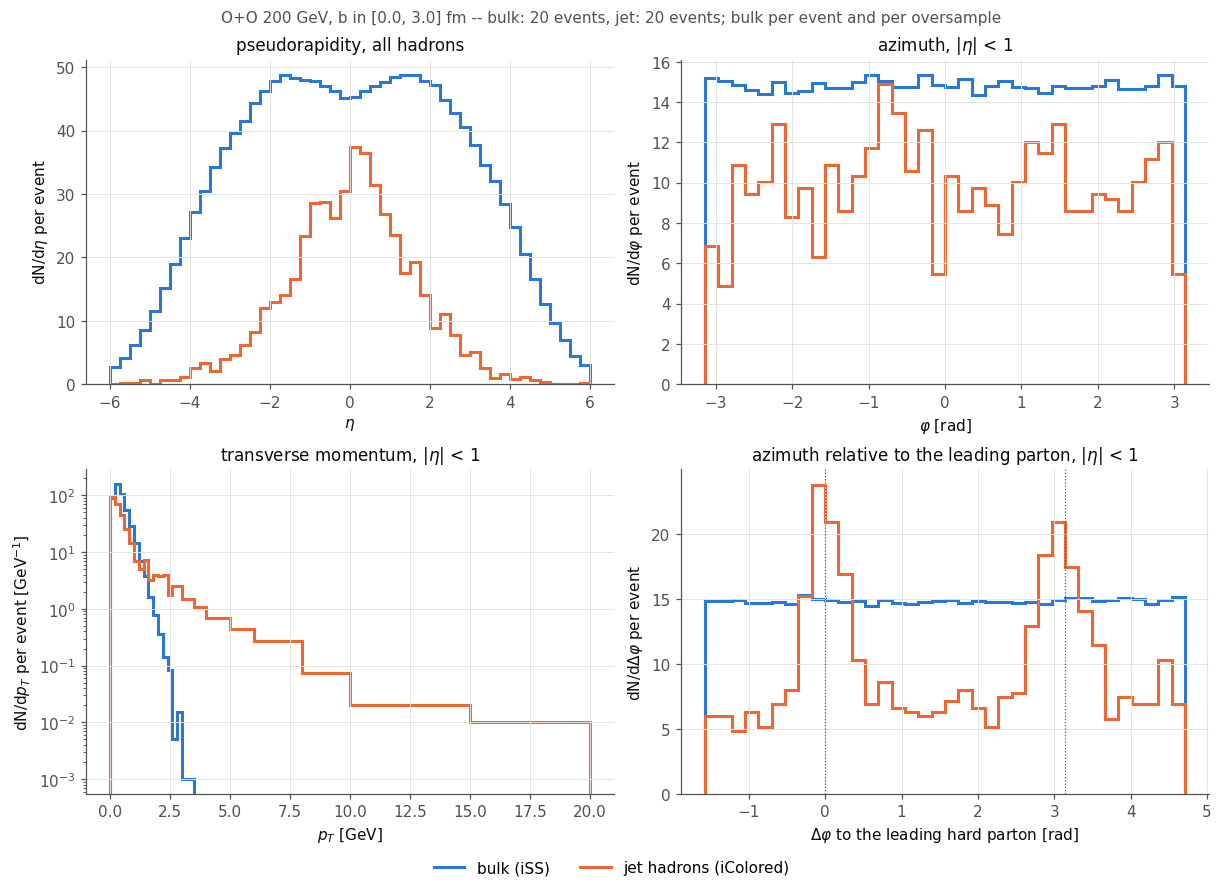

In [5]:
STYLE = {"bulk": dict(color=C_BULK, label="bulk (iSS)"),
         "jet": dict(color=C_JET, label="jet hadrons (iColored)")}

def step(ax, values, weights, bins, per_width=True, **style):
    n, edges = np.histogram(values, bins=bins, weights=weights)
    if per_width:
        n = n / np.diff(edges)
    ax.stairs(n, edges, lw=2, **style)

def wrap(dphi):
    return (dphi + 0.5 * np.pi) % (2 * np.pi) - 0.5 * np.pi       # [-pi/2, 3pi/2)

fig, ax = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
sel = "charged hadrons" if CHARGED_ONLY else "hadrons"
for tag, h in H.items():
    st = STYLE[tag]
    mid_eta = np.abs(h["eta"]) < ETA_CUT
    step(ax[0, 0], h["eta"], h["w"], np.linspace(-6, 6, 49), **st)
    step(ax[0, 1], h["phi"][mid_eta], h["w"][mid_eta], np.linspace(-np.pi, np.pi, 37), **st)
    pt_bins = np.concatenate([np.arange(0, 3, 0.2), [3, 3.5, 4, 5, 6, 8, 10, 12.5, 15, 20]])
    step(ax[1, 0], h["pt"][mid_eta], h["w"][mid_eta], pt_bins, **st)
    if phi_lead:
        has = np.array([int(e) in phi_lead for e in h["event"]])
        lead = np.array([phi_lead.get(int(e), np.nan) for e in h["event"]])
        m = mid_eta & has
        step(ax[1, 1], wrap(h["phi"][m] - lead[m]), h["w"][m],
             np.linspace(-0.5 * np.pi, 1.5 * np.pi, 37), **st)

ax[0, 0].set(xlabel="$\\eta$", ylabel=f"dN/d$\\eta$ per event", title=f"pseudorapidity, all {sel}")
ax[0, 1].set(xlabel="$\\varphi$ [rad]", ylabel="dN/d$\\varphi$ per event",
             title=f"azimuth, |$\\eta$| < {ETA_CUT:g}")
ax[1, 0].set(xlabel="$p_T$ [GeV]", ylabel="dN/d$p_T$ per event [GeV$^{-1}$]", yscale="log",
             title=f"transverse momentum, |$\\eta$| < {ETA_CUT:g}")
ax[1, 1].set(xlabel="$\\Delta\\varphi$ to the leading hard parton [rad]",
             ylabel="dN/d$\\Delta\\varphi$ per event",
             title=f"azimuth relative to the leading parton, |$\\eta$| < {ETA_CUT:g}")
ax[1, 1].axvline(0, color=C_MUTED, lw=0.8, ls=":")
ax[1, 1].axvline(np.pi, color=C_MUTED, lw=0.8, ls=":")
for a_ in ax.flat:
    a_.title.set_color(C_INK); a_.title.set_fontsize(11)
n_txt = ", ".join(f"{t}: {h['n_units']} events" for t, h in H.items())
fig.suptitle(f"{system} -- {n_txt}; bulk per event and per oversample", color=C_MUTED, fontsize=10)
fig.legend(*ax[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=2)
plt.show()

**Reading the plots.** The bulk dominates below ~2 GeV; the jet hadrons take over in the
pT tail. The bulk spectrum falls steeply (an effective slope of ~0.2 GeV between 2 and
2.5 GeV) and ends near 3 GeV only for lack of statistics: iSS has no cut there (in 20 events
x 100 samples the hardest bulk hadron had 3.3 GeV). In Δφ the jet hadrons peak at 0 (the leading parton) and at π (its partner); the
bulk is nearly flat, its small modulation is the medium's response to the event geometry,
not to the jet (there is no jet deposition in this production). With few events the jet
curves are noisy: the jet file has one hadronization per event.

In [6]:
# per-event numbers (hydro diag + hadron multiplicities at |eta| < 0.5); with ISR
# E_strings + E_sub + the hard pair's remnants = Npart sqrt(s)/2
rows = []
for i in range(nev_hydro):
    ev = int(diag["event"][i]) if "event" in diag else i
    r = {"event": ev, "pTHat": diag["pthat"][i], "Npart": diag["glauber_npart"][i],
         "Ncoll": diag["glauber_ncoll"][i], "b [fm]": diag["glauber_b"][i]}
    # ISR energy bookkeeping (production files from 2026-10-10 on): energy taken from the
    # colliding nucleons by the hard process, and what the strings hand to MUSIC
    for key, label in (("isr_sub_E_total", "E_sub [GeV]"), ("strings_E_total", "E_strings")):
        if key in diag:
            r[label] = diag[key][i]
    for tag, h in H.items():
        m = (h["event"] == ev) & (np.abs(h["eta"]) < 0.5)
        r[f"{tag} dN/deta"] = h["w"][m].sum() * h["n_units"]
    rows.append(r)
keys = list(rows[0])
print("  ".join(f"{k:>14s}" for k in keys))
for r in rows:
    print("  ".join(f"{r[k]:14.2f}" if isinstance(r[k], float) else f"{r[k]:14}" for k in keys))

         event           pTHat           Npart           Ncoll          b [fm]     E_sub [GeV]       E_strings    bulk dN/deta     jet dN/deta
             0           21.90           20.00           20.00            2.86           89.74         1855.66           34.72           37.00
             1           25.79           19.00           22.00            2.07          136.28         1722.12           50.09           24.00
             2           20.30           13.00           18.00            2.61          133.52         1142.54           33.92           37.00
             3           22.63           20.00           23.00            2.15           65.65         1882.31           34.39           22.00
             4           24.24           23.00           25.00            1.59          114.13         2155.24           64.92           14.00
             5           23.06           23.00           28.00            2.01           57.62         2217.24           51.80           29.00